In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

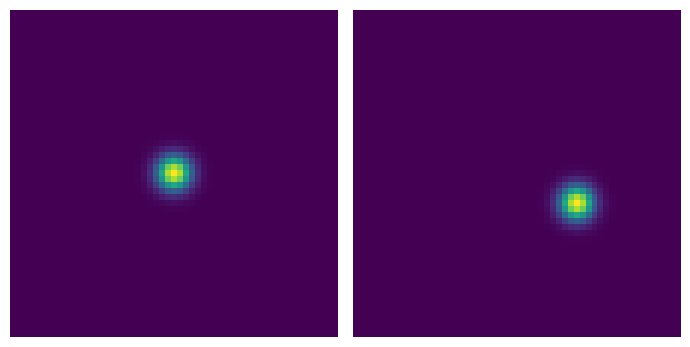

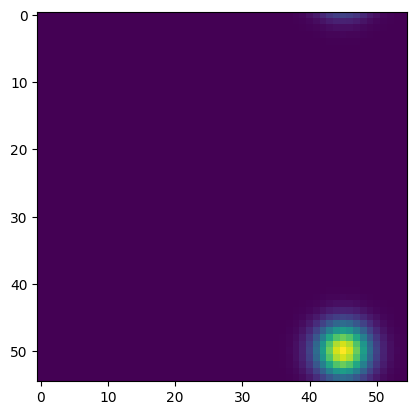

50 45


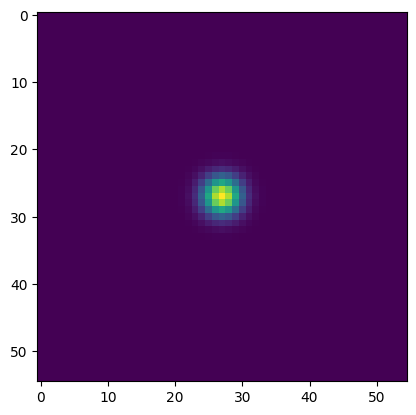

1.0813728179485312e-19


In [2]:
L = 55

sigma = 2

f = utils.generate_centered_gaussian(L, d=2, sigma=sigma)

ty, tx = 5, 10

g = transforms.translate_2d(f, ty, tx)

f = signals.Signal(f, d=2).preprocess_signals()[0]
g = signals.Signal(g, d=2).preprocess_signals()[0]

plots.two_imshow(f, g)

# c = np.fft.ifft2(np.conj(np.fft.fft2(f)) * np.fft.fft2(g)).real
c = np.fft.ifft2(np.fft.fft2(f) * np.conj(np.fft.fft2(g))).real

min_y, min_x = np.unravel_index(np.argmax(c, axis=None), c.shape)

plt.imshow(c)
plt.show()

print(min_y, min_x)

z = transforms.translate_2d(g, min_y, min_x)

plt.imshow(z)
plt.show()

print(np.linalg.norm(f - z))

In [3]:
A = np.array([[1, 2],
              [3, 4]])

# B = np.array([[2, 1],
#               [4, 3]])

B = np.array([[2],
              [4]])


np.fft.ifft2(np.conj(np.fft.fft2(A)) * np.fft.fft2(B)).real

array([[14., 20.],
       [10., 16.]])

In [4]:
# n = 2
# A = np.arange(n*n*n).reshape(n,n,n)

# A

# A.sum(axis=1)

In [5]:
A = np.array([[1, 2],
              [3, 4]])

ny, nx = A.shape

c1 = np.fft.ifft2(np.fft.fft2(A) * np.conj(np.fft.fft2(A))).real


c2 = np.zeros(A.shape)

for ty in range(ny):
    for tx in range(nx):

        a = transforms.translate_2d(A, ty, tx)

        print(a)
        print('\n')

        c2[ty, tx] = np.sum(A * a)

[[1 2]
 [3 4]]


[[2 1]
 [4 3]]


[[3 4]
 [1 2]]


[[4 3]
 [2 1]]




In [6]:
c1

array([[30., 28.],
       [22., 20.]])

In [7]:
c2

array([[30., 28.],
       [22., 20.]])